In [31]:
import cv2 

In [32]:
from matplotlib import pyplot as plt
import numpy as np

In [33]:
image =cv2.imread('beautifulmaleperson.jpg', cv2.IMREAD_GRAYSCALE)

In [34]:
if image is None:
    print('error')
    exit()

print(f'image shape: {image.shape}')

image shape: (997, 1185)


Text(0.5, 1.0, 'original image')

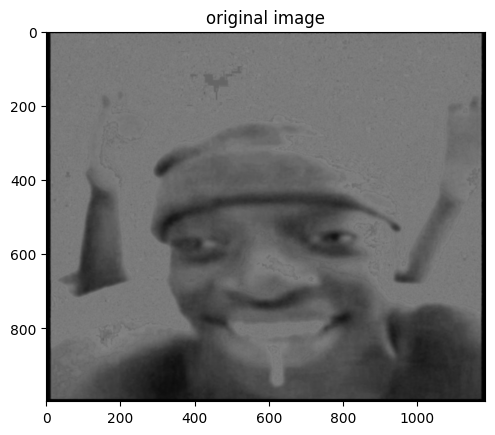

In [35]:
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('original image')


In [36]:
resized_image = cv2.resize(image,(300,200))

In [37]:
(h,w) = image.shape[:2]
center = (w // 2, h // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
rotated_image = cv2.warpAffine(image, rotation_matrix, (w,h))


<function matplotlib.pyplot.show(close=None, block=None)>

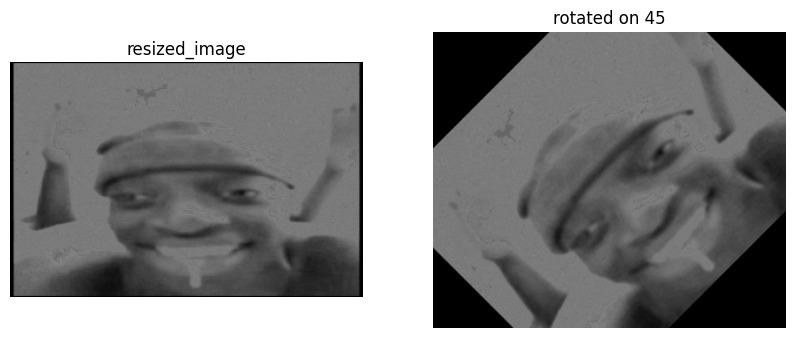

In [38]:
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(resized_image,cv2.COLOR_BGR2RGB))
plt.title('resized_image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rotated_image,cv2.COLOR_BGR2RGB))
plt.title('rotated on 45')
plt.axis('off')
plt.show


In [39]:
from sklearn.cluster import KMeans

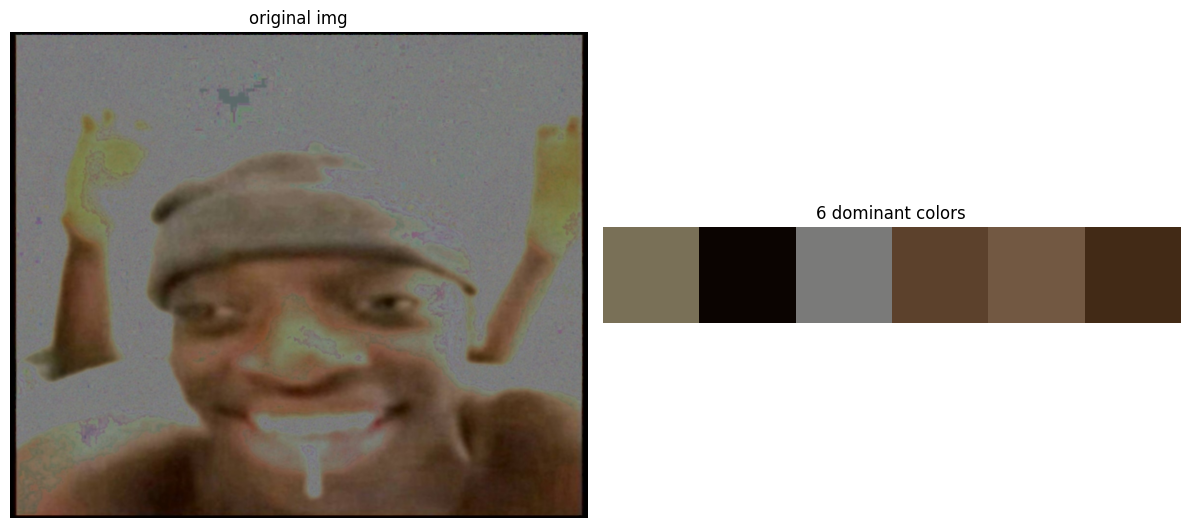

rgb_colors[[121 112  87]
 [ 11   4   1]
 [122 122 121]
 [ 92  65  44]
 [114  88  66]
 [ 66  42  22]]


In [40]:
def extract_dominant_colors (image_path, n_colors=5):
    img = cv2. imread (image_path)
    img = cv2. cvtColor (img, cv2. COLOR_BGR2RGB)
    pixels = img.reshape( (-1, 3))

    kmeans = KMeans(n_clusters=n_colors)
    kmeans.fit(pixels)

    colors = kmeans.cluster_centers_.astype(np.uint8)
    return colors, img

def show_image_and_palette(colors, original_img) :
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    ax1.imshow(original_img)
    ax1.axis('off')
    ax1.set_title('original img')

    ax2.imshow([colors])
    ax2.axis('off')
    ax2.set_title(f'{len(colors)} dominant colors')

    plt.tight_layout()
    plt.show()

    def print_rgb_colors(colors):
        for color in colors:
            r, g, b = color
            print(f'rgb({r}, {g}, {b})')


image_path = '/Users/makardmitrievich/Desktop/Machine Learning/opencv/beautifulmaleperson.jpg'
n_colors = 6 
dominant_colors, original_img = extract_dominant_colors(image_path, n_colors)
show_image_and_palette(dominant_colors,original_img)
print(f'rgb_colors{dominant_colors}')


In [41]:
def geometric_mean_filter(img, window_size):
    rows, cols, channels = img.shape
    filtered_img = np.zeros_like(img)
    for i in range(half_window, rows - half_window):
        for j in range(half_window, cols - half_window):
            for c in range(channels):
                window = img[i-half_window:i+half_window+1, j-half_window:j+half_window+1, c]
                geometric_mean = np.prod(window) ** (1 / (window_size * window_size))
                filtered_img[i, j, c] = geometric_mean
    return filtered_img

if __name__ == "__main__":
    img = cv2.imread('beautifulmaleperson.jpg')
    
    window_size = 3
    half_window = window_size // 2
    
    padded_img = cv2.copyMakeBorder(
        img,
        half_window,
        half_window,
        half_window,
        half_window,
        borderType=cv2.BORDER_CONSTANT,
        value=[0, 0, 0]
    )
    
    filtered_img = geometric_mean_filter(padded_img, window_size)
    
    cv2.imwrite('beautifulmaleperson.jpg', filtered_img)

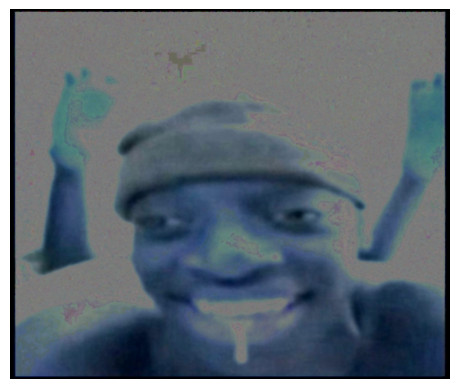

In [42]:
plt.imshow(filtered_img)
plt.axis('off')
plt.show()

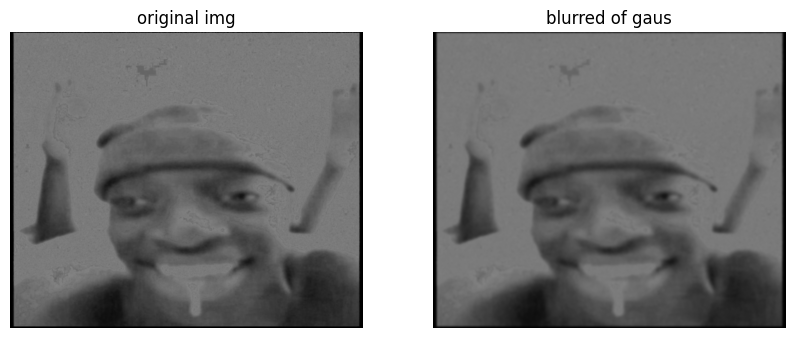

In [43]:
blurred = cv2.GaussianBlur(image, (15, 15), 0)
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('original img')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB))
plt.title('blurred of gaus')
plt.axis('off')
plt.show()

In [44]:
from scipy.spatial.distance import cdist
from skimage import io, data, segmentation, color, transform
from sklearn.decomposition import PCA

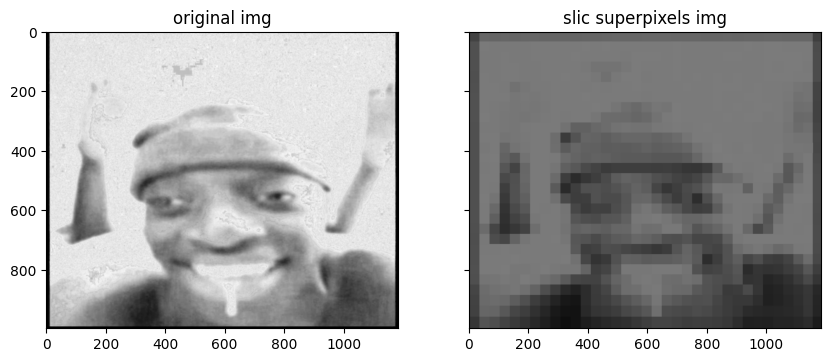

In [45]:
from skimage import segmentation, color
import matplotlib.pyplot as plt


segments_slic = segmentation.slic(
    image, 
    n_segments=1000, 
    compactness=40, 
    slic_zero=True,
    channel_axis=None  
)

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
ax[0].imshow(image, cmap='gray')  
ax[0].set_title('original img')
ax[1].imshow(color.label2rgb(segments_slic, image, kind='avg'))
ax[1].set_title('slic superpixels img')
plt.show()